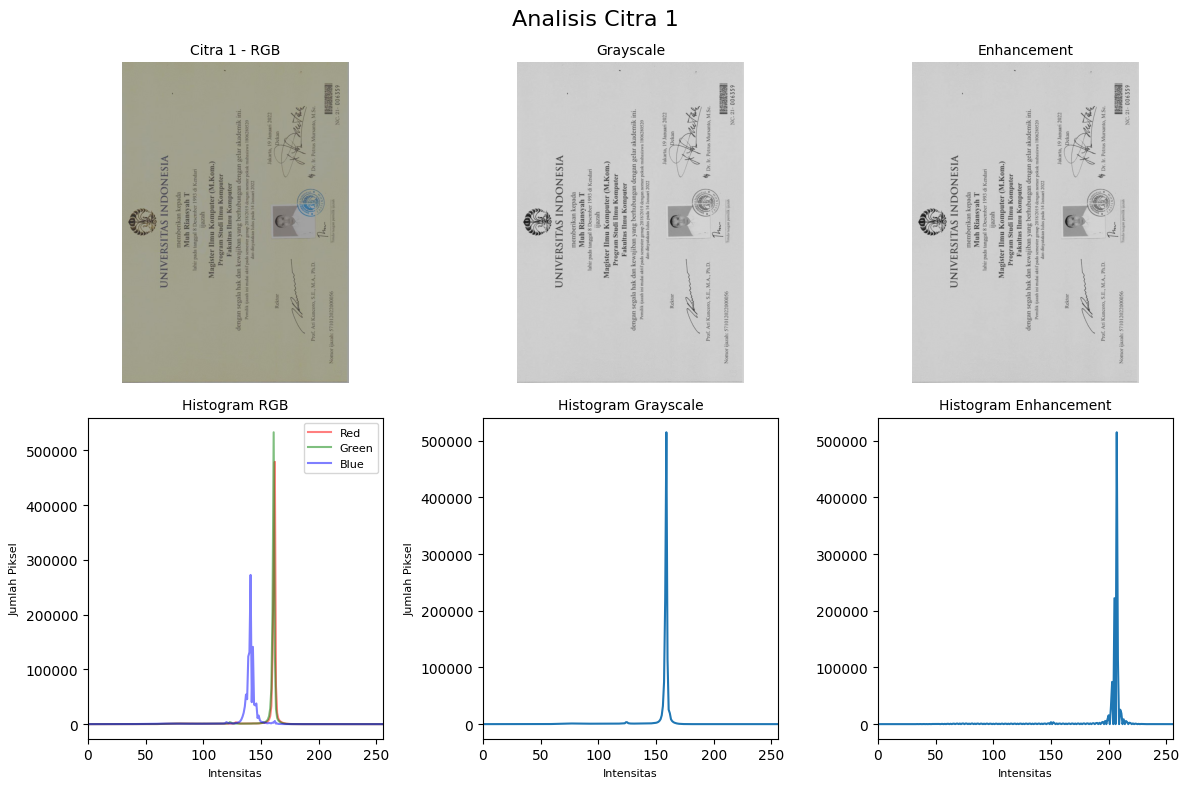

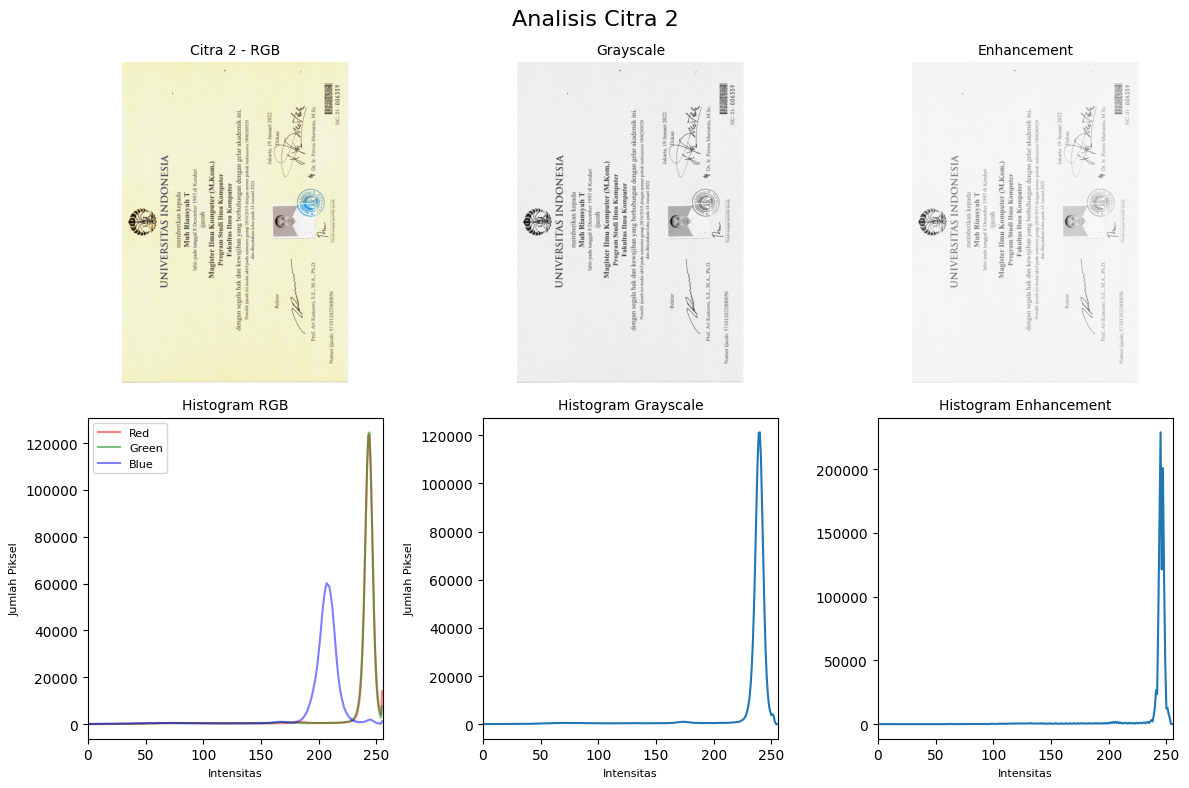

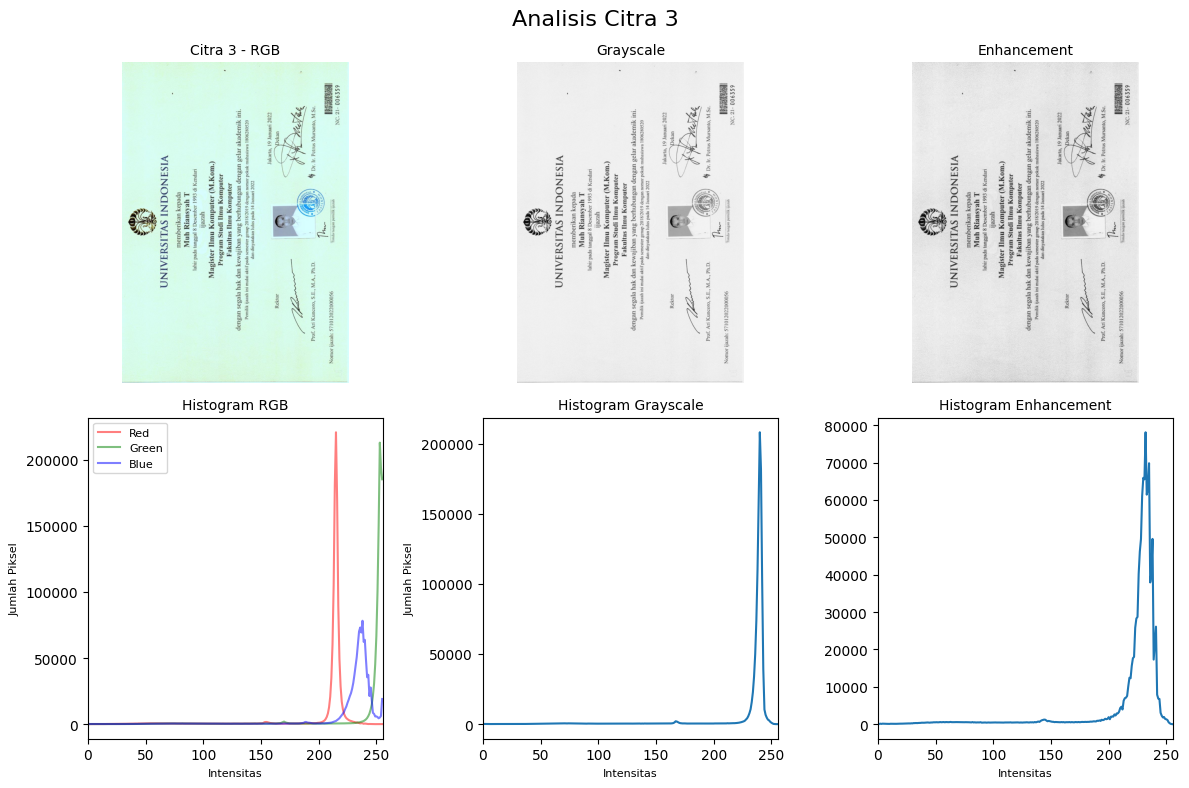

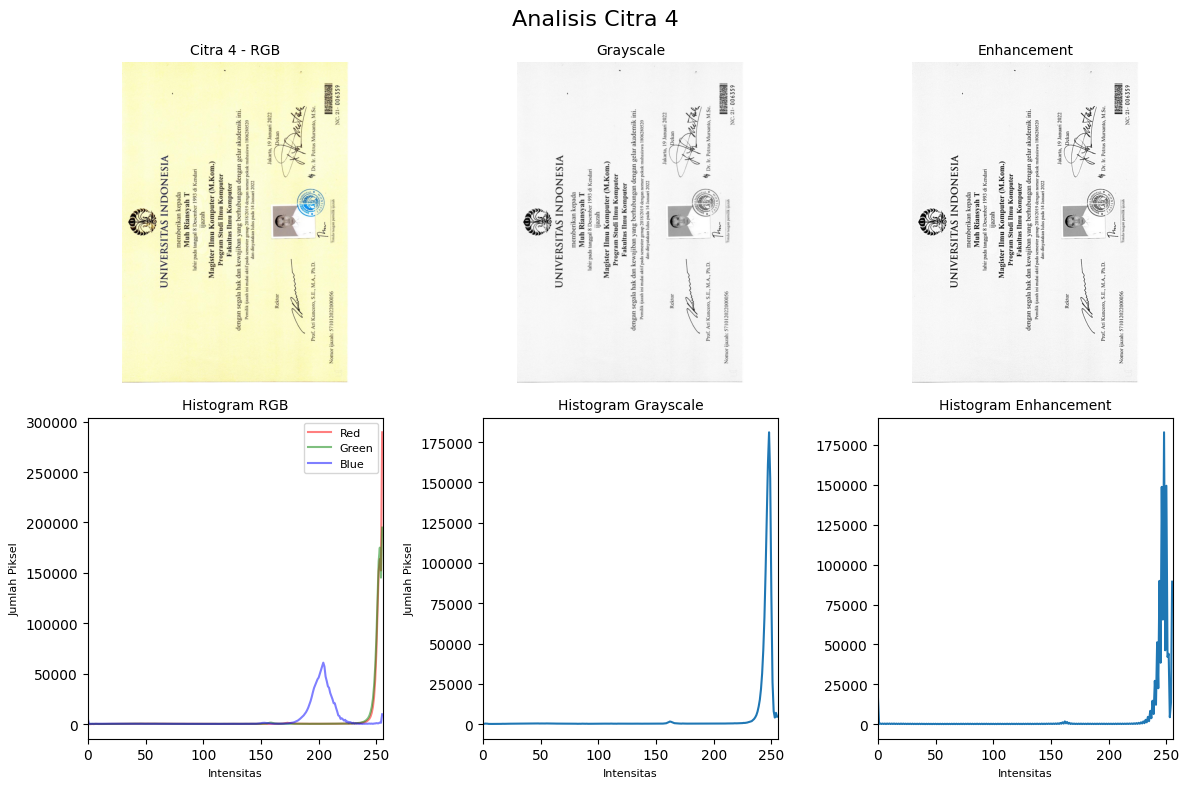

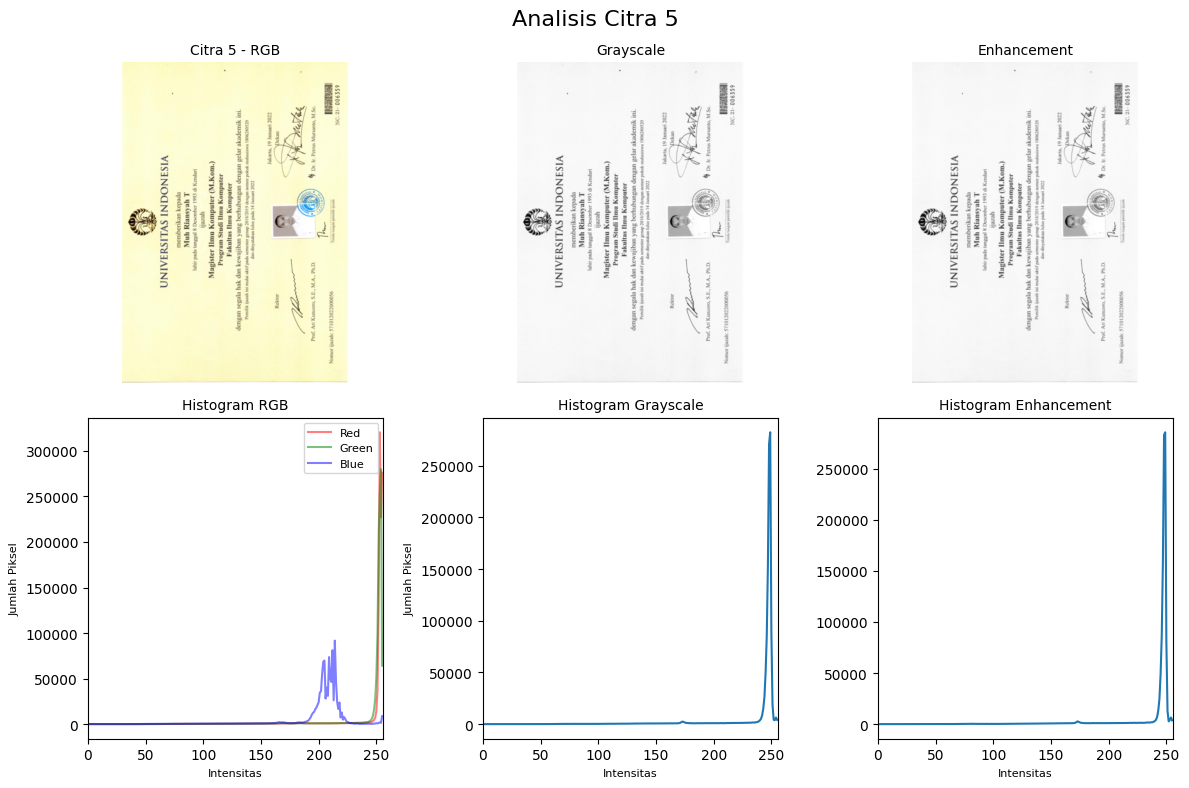

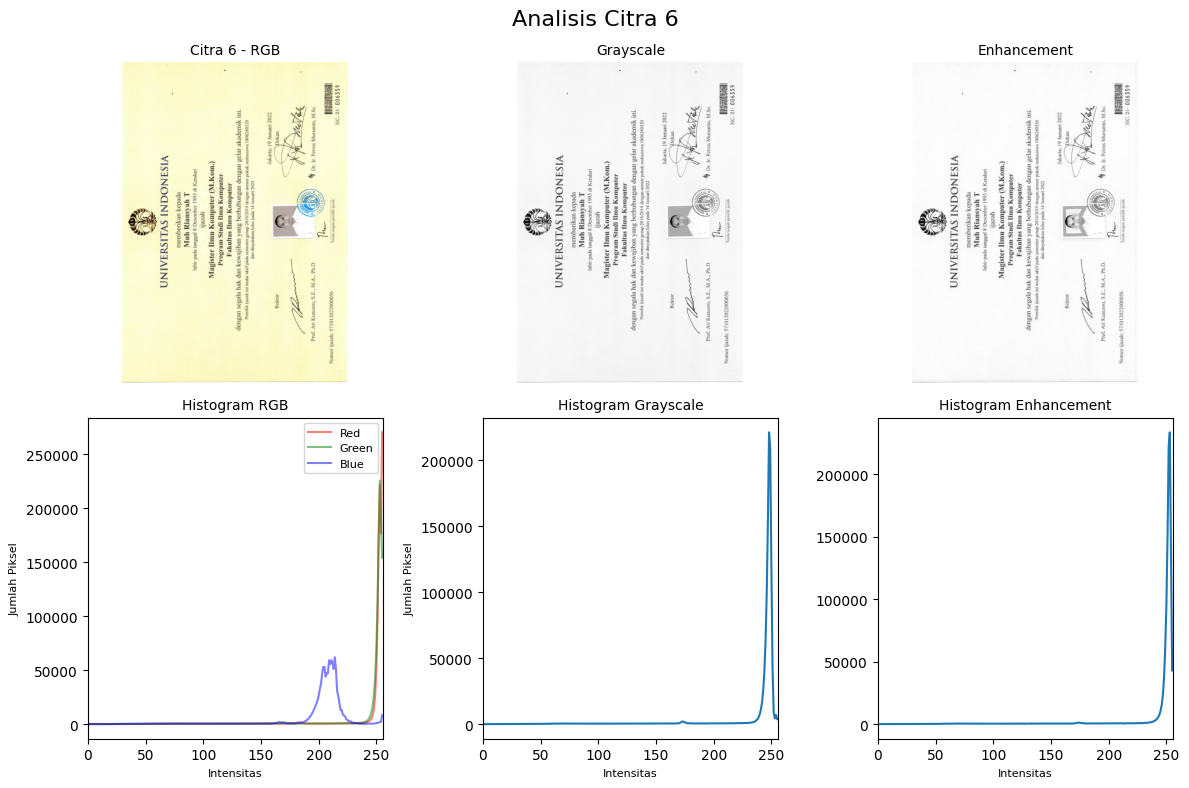

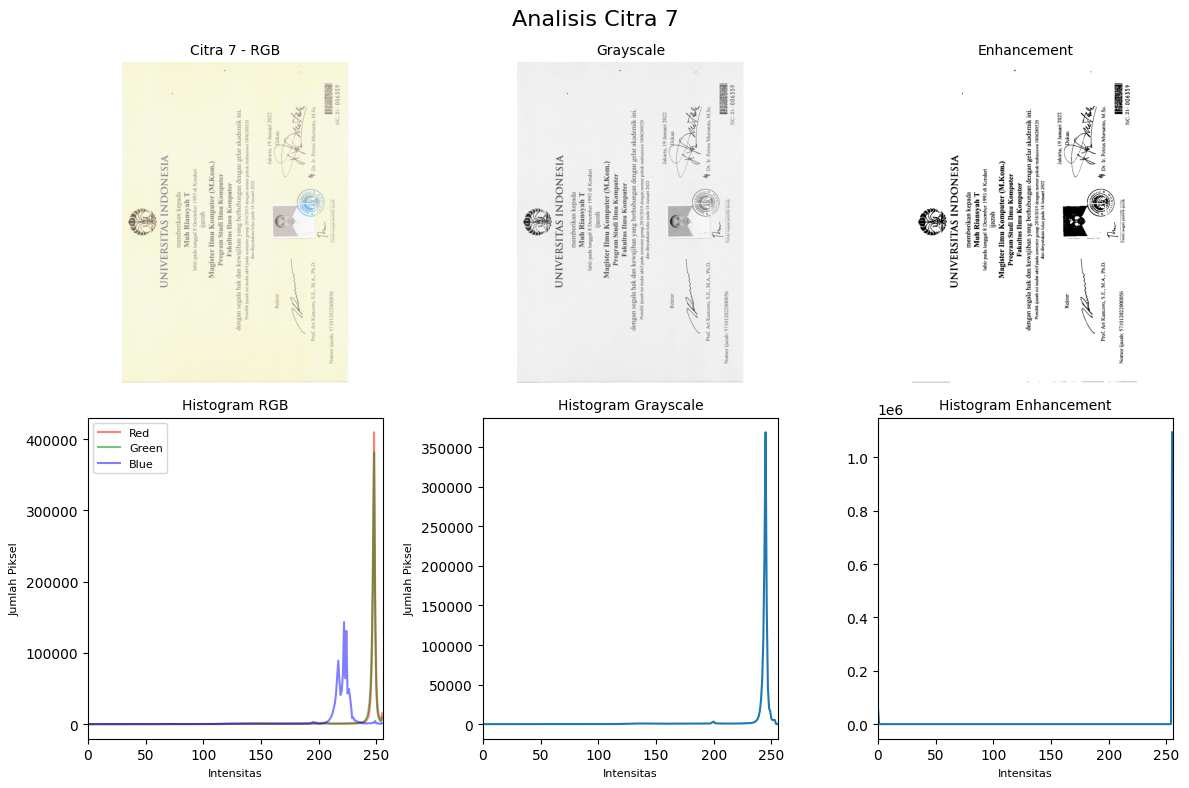

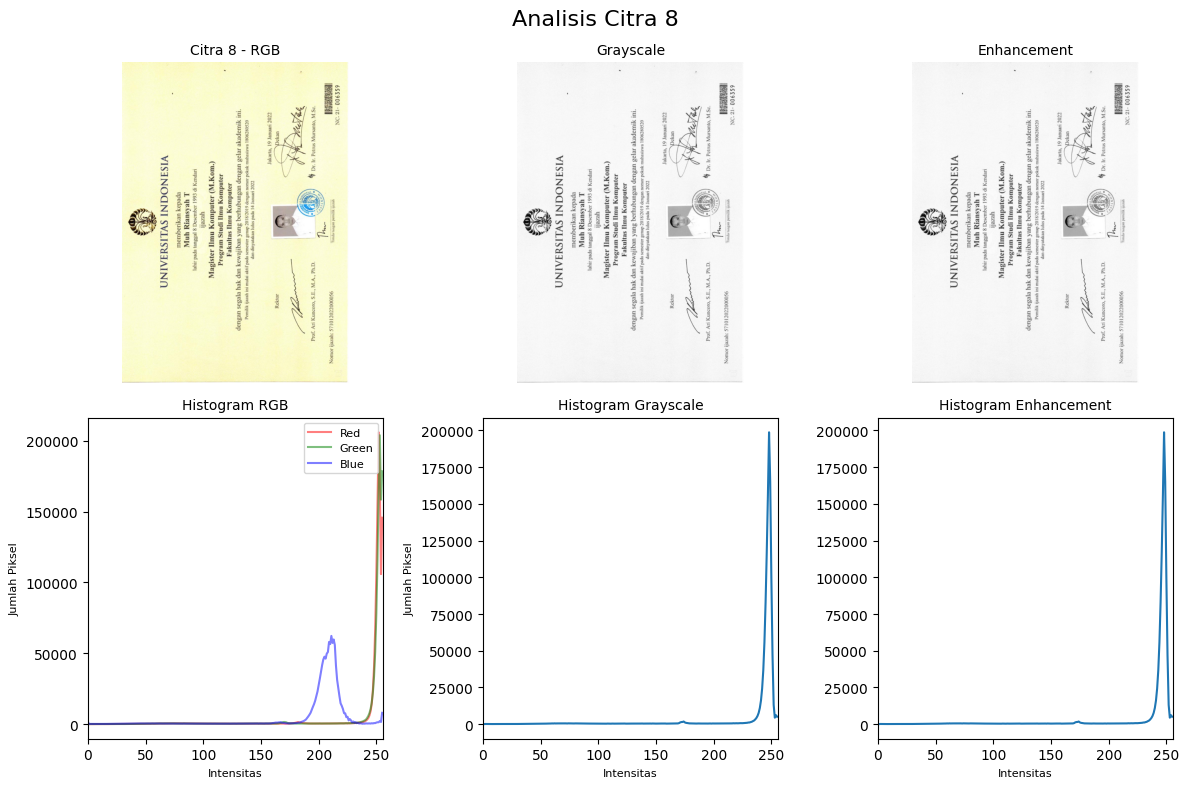

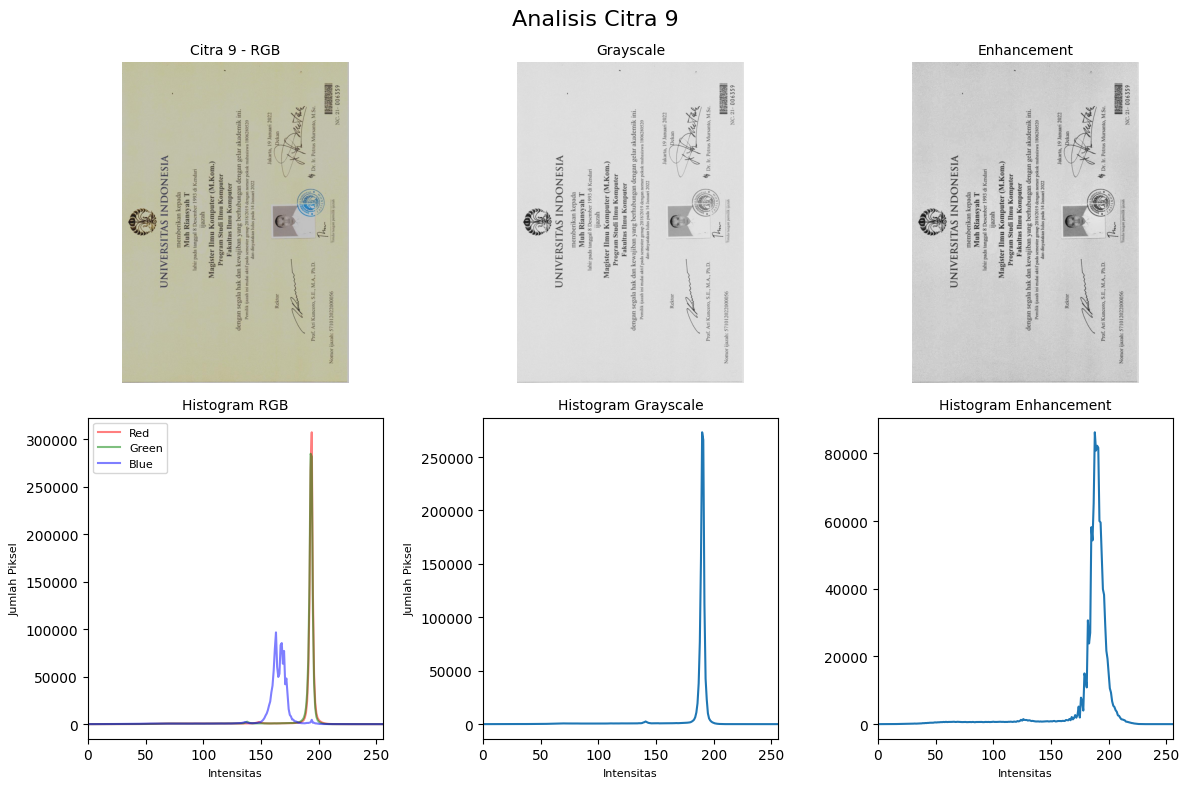

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Daftar nama file gambar (Sudah ditambah ijazah8.jpg dan ijazah9.jpg)
image_paths = [
    'ijazah1.jpg', 'ijazah2.jpg', 'ijazah3.jpg',
    'ijazah4.jpg', 'ijazah5.jpg', 'ijazah6.jpg', 'ijazah7.jpg',
    'ijazah8.jpg', 'ijazah9.jpg'
]

# Loop untuk memproses dan menampilkan tiap gambar satu per satu
for idx, img_path in enumerate(image_paths, start=1):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        print(f"Gambar {img_path} tidak ditemukan!")
        continue

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 1. Penerapan Metode Enhancement Spesifik untuk Tiap Citra
    if idx == 1:
        img_enhanced = cv2.normalize(img_gray, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    elif idx == 2:
        gamma = 1.8
        inv_gamma = 1.0 / gamma
        table = np.array([((x / 255.0) ** inv_gamma) * 255 for x in np.arange(0, 256)]).astype("uint8")
        img_enhanced = cv2.LUT(img_gray, table)
    elif idx == 3:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img_enhanced = clahe.apply(img_gray)
    elif idx == 4:
        gaussian = cv2.GaussianBlur(img_gray, (9, 9), 10.0)
        img_enhanced = cv2.addWeighted(img_gray, 1.5, gaussian, -0.5, 0)
    elif idx == 5:
        img_enhanced = cv2.medianBlur(img_gray, 3)
    elif idx == 6:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 25))
        background = cv2.morphologyEx(img_gray, cv2.MORPH_DILATE, kernel)
        img_enhanced = cv2.divide(img_gray, background, scale=255)
    elif idx == 7:
        _, img_enhanced = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    elif idx == 8:
        # Enhancement khusus Citra 8 (Contrast Stretching)
        img_enhanced = cv2.normalize(img_gray, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    elif idx == 9:
        # Enhancement khusus Citra 9 (CLAHE)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img_enhanced = clahe.apply(img_gray)

    # 2. Plotting Grid 2x3 Persis Seperti Contoh Temanmu
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    fig.suptitle(f'Analisis Citra {idx}', fontsize=16)

    # Baris 1: Gambar
    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title(f'Citra {idx} - RGB', fontsize=10)
    axes[0, 0].axis('off')

    axes[0, 1].imshow(img_gray, cmap='gray')
    axes[0, 1].set_title('Grayscale', fontsize=10)
    axes[0, 1].axis('off')

    axes[0, 2].imshow(img_enhanced, cmap='gray')
    axes[0, 2].set_title('Enhancement', fontsize=10)
    axes[0, 2].axis('off')

    # Baris 2: Histogram
    # Histogram RGB (Red, Green, Blue)
    colors = ('red', 'green', 'blue')
    labels = ('Red', 'Green', 'Blue')
    for i, (col, label) in enumerate(zip(colors, labels)):
        hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
        axes[1, 0].plot(hist, color=col, alpha=0.5, label=label)
    axes[1, 0].set_title('Histogram RGB', fontsize=10)
    axes[1, 0].set_xlabel('Intensitas', fontsize=8)
    axes[1, 0].set_ylabel('Jumlah Piksel', fontsize=8)
    axes[1, 0].set_xlim([0, 256])
    axes[1, 0].legend(fontsize=8)

    # Histogram Grayscale
    hist_gray = cv2.calcHist([img_gray], [0], None, [256], [0, 256])
    axes[1, 1].plot(hist_gray)
    axes[1, 1].set_title('Histogram Grayscale', fontsize=10)
    axes[1, 1].set_xlabel('Intensitas', fontsize=8)
    axes[1, 1].set_ylabel('Jumlah Piksel', fontsize=8)
    axes[1, 1].set_xlim([0, 256])

    # Histogram Enhancement
    hist_enhanced = cv2.calcHist([img_enhanced], [0], None, [256], [0, 256])
    axes[1, 2].plot(hist_enhanced)
    axes[1, 2].set_title('Histogram Enhancement', fontsize=10)
    axes[1, 2].set_xlabel('Intensitas', fontsize=8)
    axes[1, 2].set_xlim([0, 256])

    plt.tight_layout()
    # Simpan otomatis gambar tiap citra (misal: analisis_citra_1.png s/d analisis_citra_9.png)
    plt.savefig(f'analisis_citra_{idx}.png', dpi=300)
    plt.show()

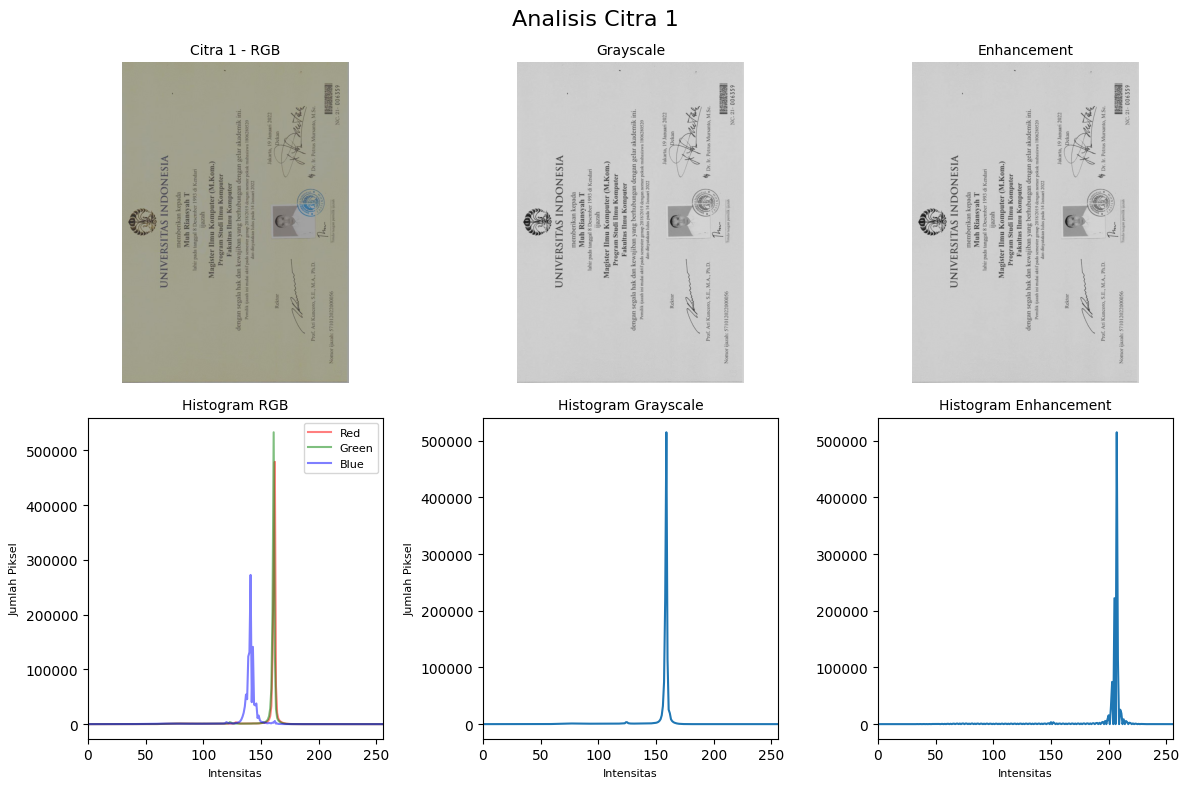

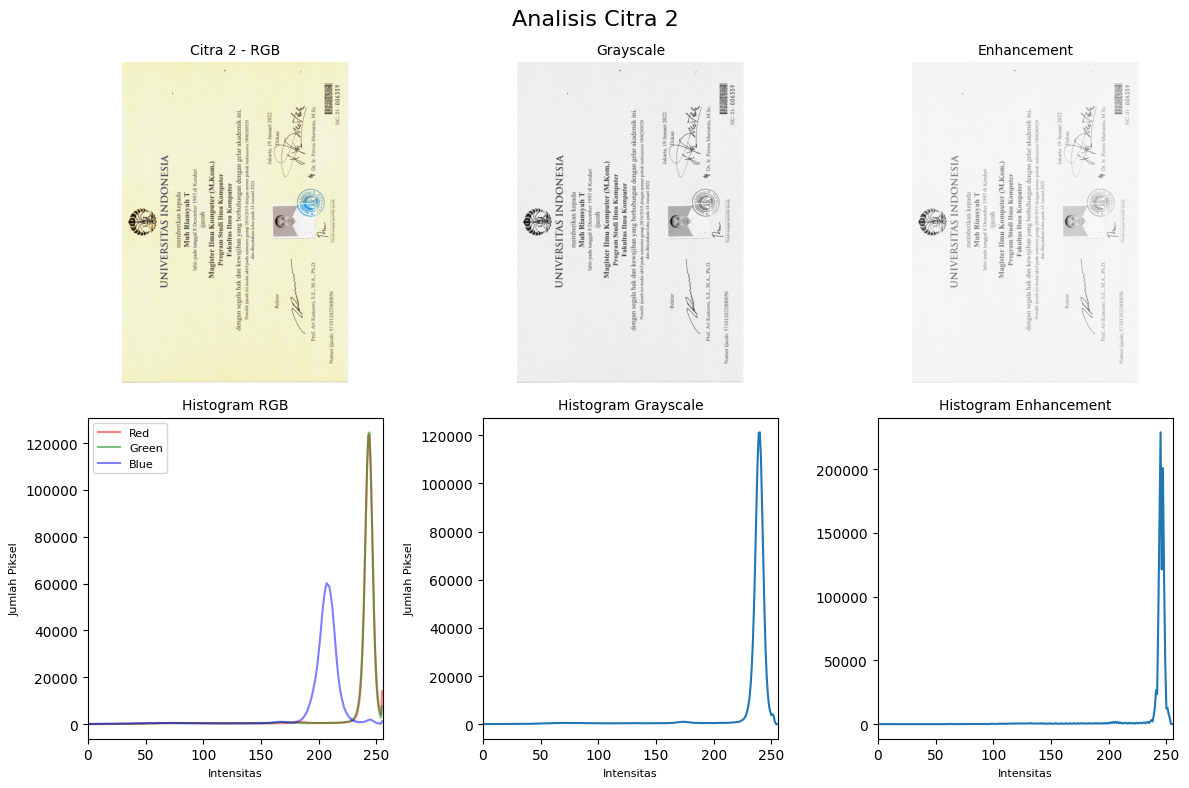

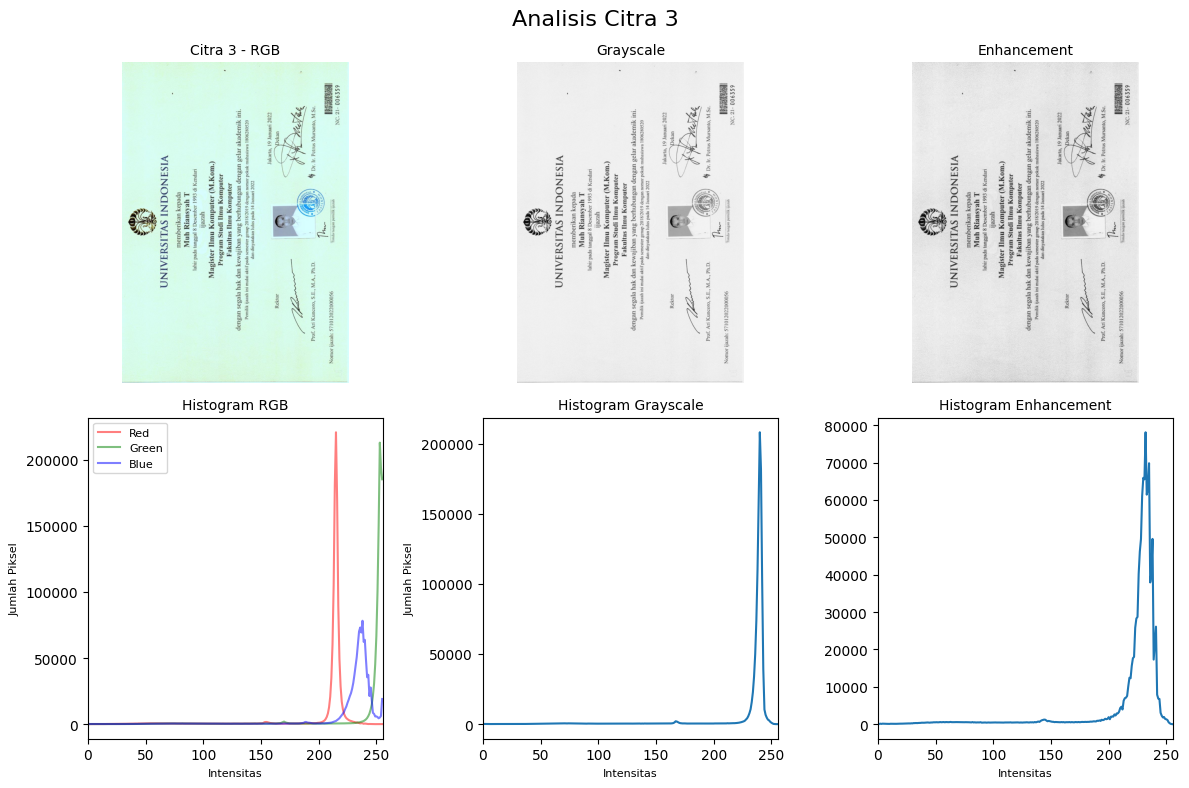

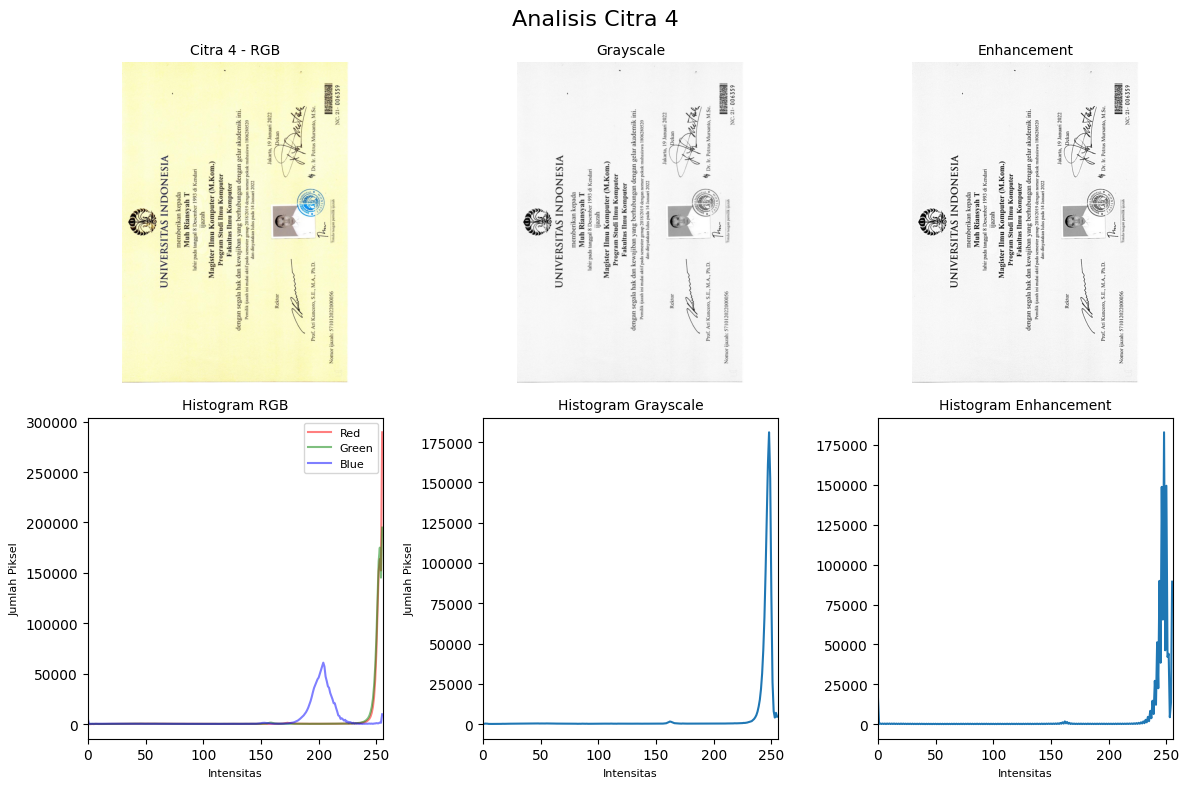

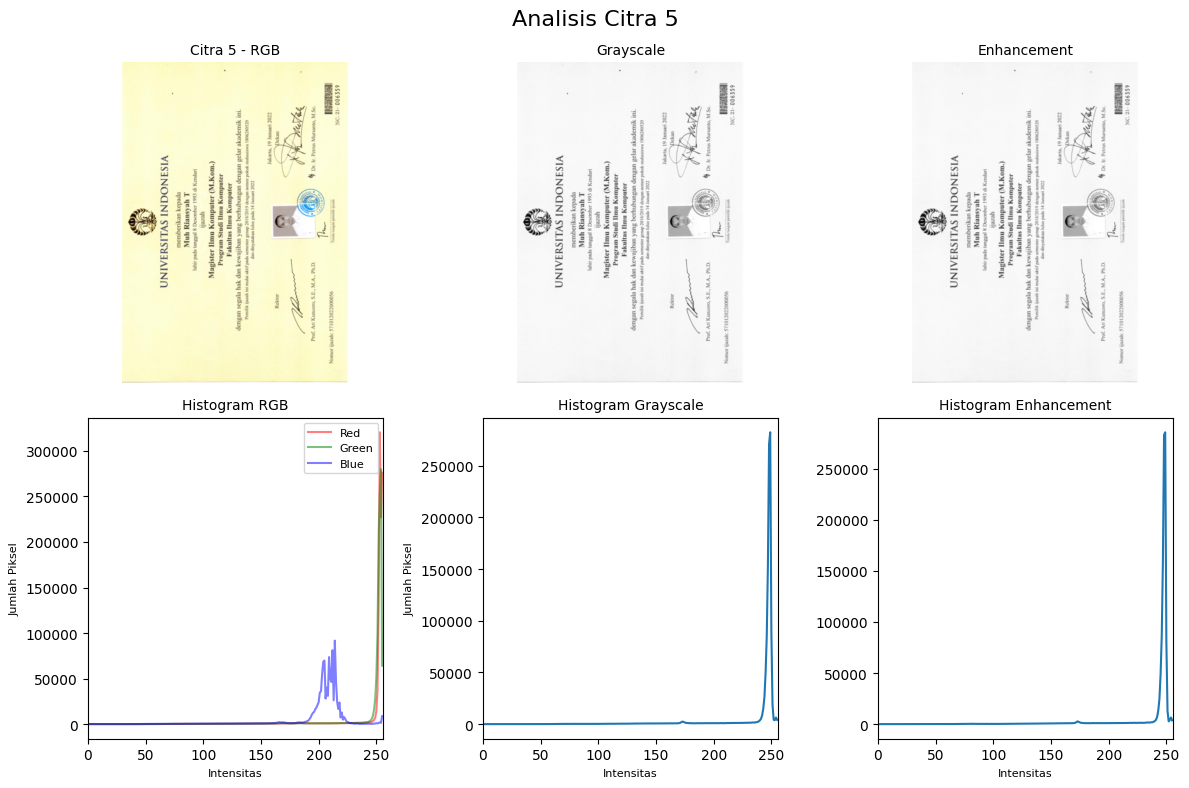

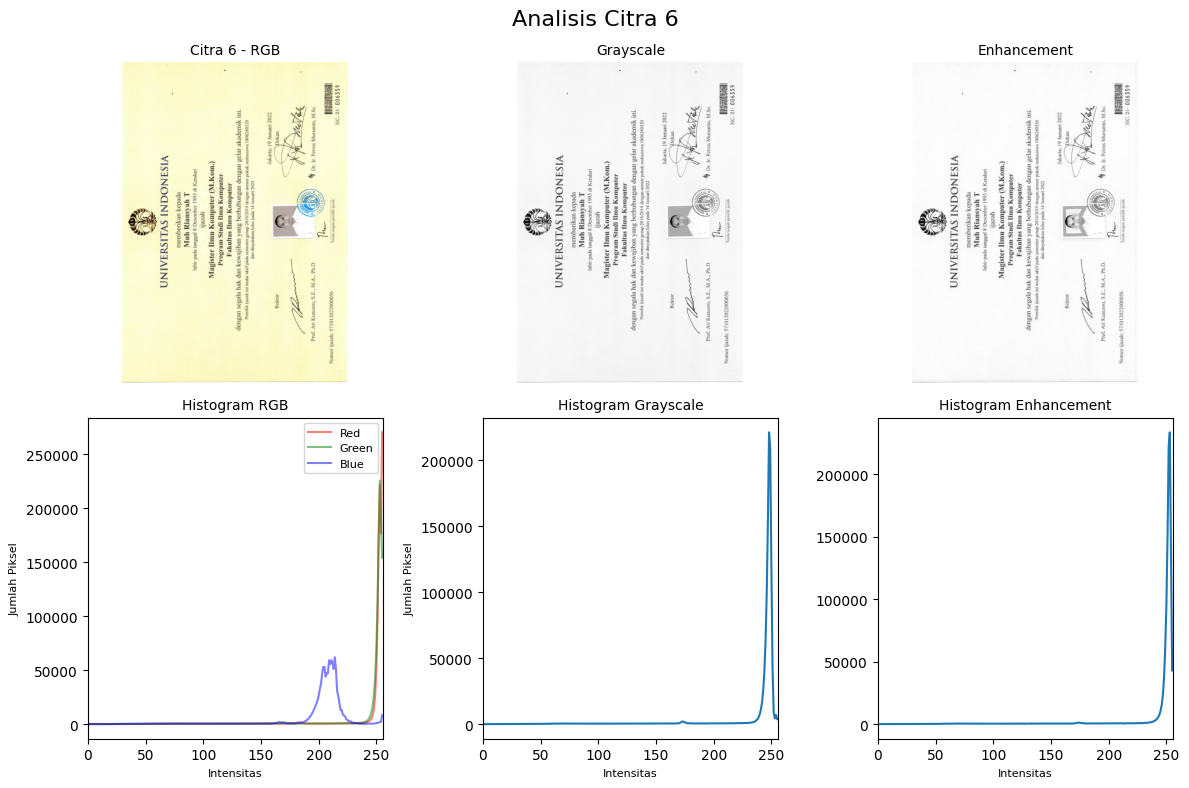

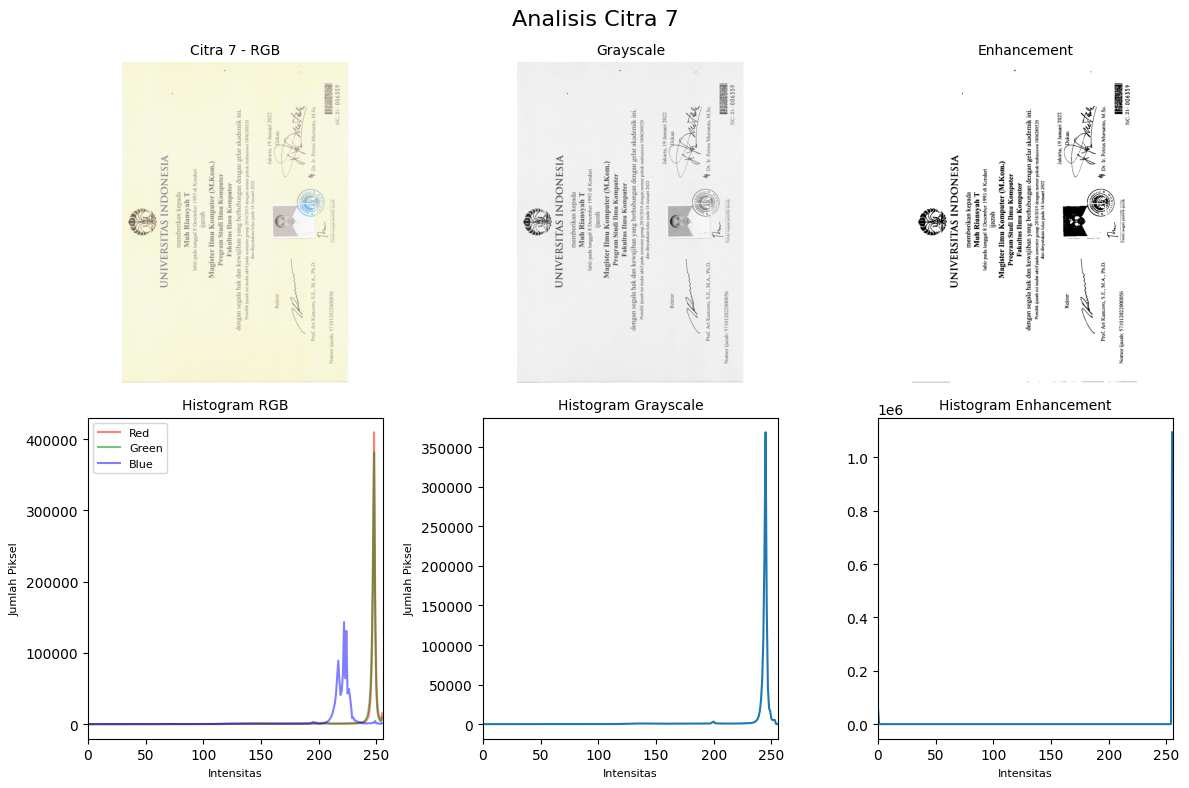

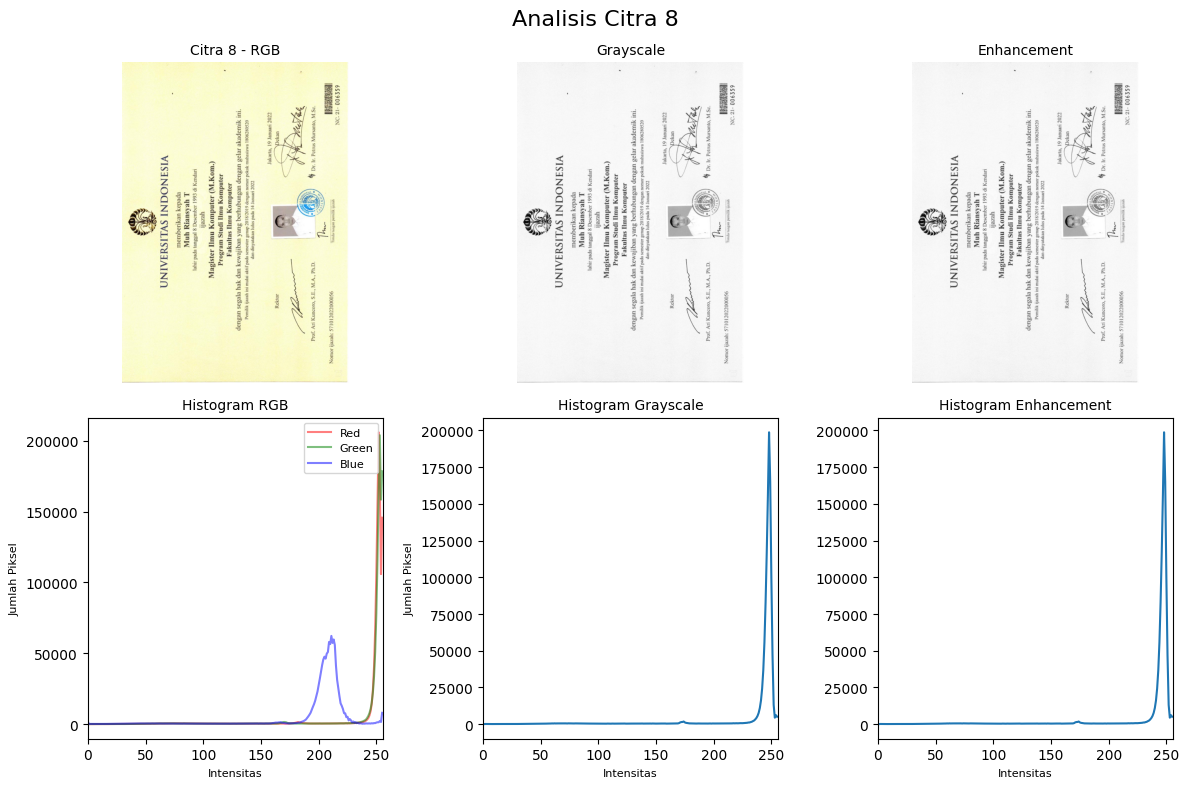

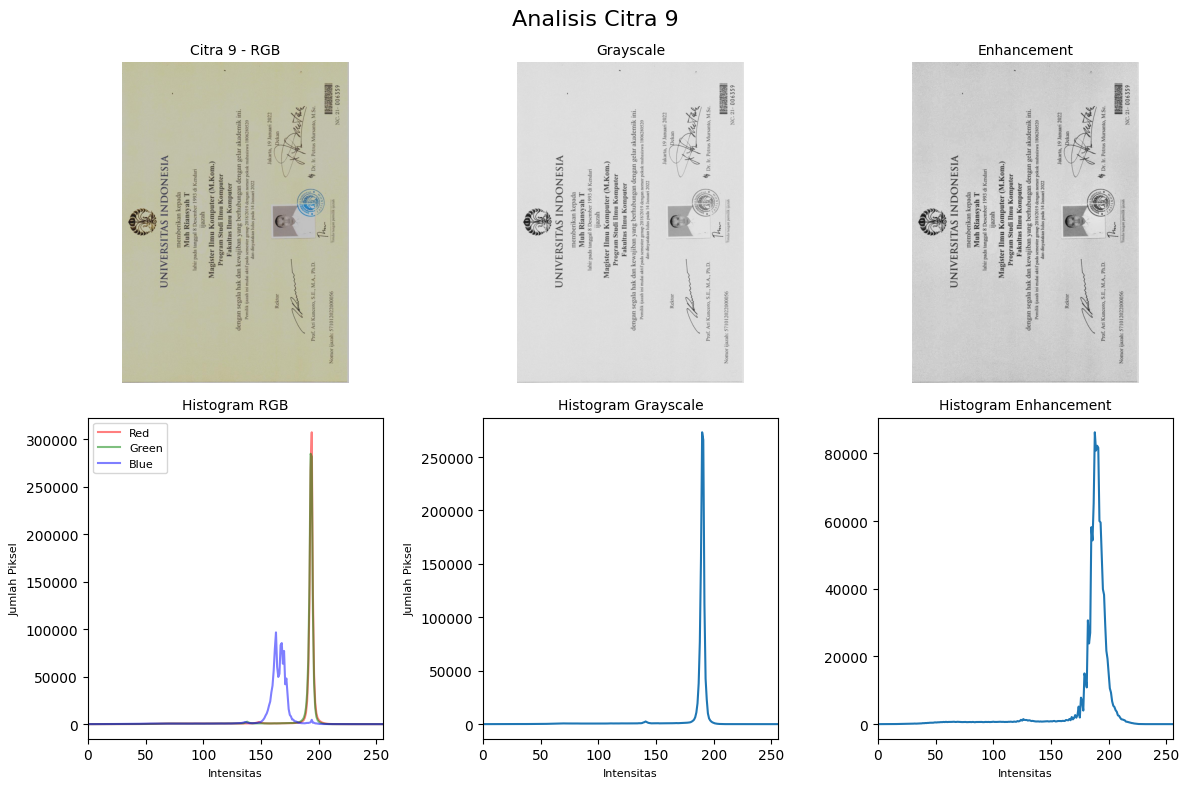


Citra  | Mean   | SD     | P1-P99     | >245   | Masalah Utama             | Enhancement         
1      | 154.9  | 15.1   | 76–165     | 0.0%   | Terlalu gelap             | Contrast Stretching 
2      | 231.7  | 31.1   | 67–250     | 4.9%   | Cenderung terlalu terang  | Gamma Correction (g=1.8)
3      | 231.1  | 32.0   | 63–246     | 1.2%   | Terang dengan color cast  | CLAHE               
4      | 237.2  | 37.2   | 40–254     | 65.0%  | Teks kurang tajam         | Unsharp Masking     
5      | 239.6  | 28.3   | 100–253    | 79.3%  | Noise halus pada kertas   | Median Filter (3x3) 
6      | 239.1  | 31.9   | 72–253     | 75.4%  | Pencahayaan tidak merata  | Top-Hat Subtraction 
7      | 239.6  | 19.9   | 136–251    | 21.8%  | Latar kusam, kontras tipis | Otsu Binarization   
8      | 238.7  | 33.1   | 65–253     | 70.1%  | Rentang dinamis belum optimal | Contrast Stretching 
9      | 184.6  | 21.7   | 71–196     | 0.0%   | Terlalu gelap / kusam     | CLAHE               


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Daftar nama file gambar
image_paths = [
    'ijazah1.jpg', 'ijazah2.jpg', 'ijazah3.jpg',
    'ijazah4.jpg', 'ijazah5.jpg', 'ijazah6.jpg', 'ijazah7.jpg',
    'ijazah8.jpg', 'ijazah9.jpg'
]

# List untuk menyimpan ringkasan statistik untuk tabel
ringkasan_statistik = []

# Loop untuk memproses dan menampilkan tiap gambar satu per satu
for idx, img_path in enumerate(image_paths, start=1):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        print(f"Gambar {img_path} tidak ditemukan!")
        continue

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # --- HITUNG STATISTIK KUANTITATIF CITRA GRAYSCALE (SEBELUM ENHANCEMENT) ---
    mean_val = np.mean(img_gray)
    sd_val = np.std(img_gray)
    p1, p99 = np.percentile(img_gray, [1, 99])
    overexposed_pct = (np.sum(img_gray > 245) / img_gray.size) * 100

    # 1. Penerapan Metode Enhancement Spesifik untuk Tiap Citra
    if idx == 1:
        img_enhanced = cv2.normalize(img_gray, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
        masalah = "Terlalu gelap"
        metode = "Contrast Stretching"
    elif idx == 2:
        gamma = 1.8
        inv_gamma = 1.0 / gamma
        table = np.array([((x / 255.0) ** inv_gamma) * 255 for x in np.arange(0, 256)]).astype("uint8")
        img_enhanced = cv2.LUT(img_gray, table)
        masalah = "Cenderung terlalu terang"
        metode = "Gamma Correction (g=1.8)"
    elif idx == 3:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img_enhanced = clahe.apply(img_gray)
        masalah = "Terang dengan color cast"
        metode = "CLAHE"
    elif idx == 4:
        gaussian = cv2.GaussianBlur(img_gray, (9, 9), 10.0)
        img_enhanced = cv2.addWeighted(img_gray, 1.5, gaussian, -0.5, 0)
        masalah = "Teks kurang tajam"
        metode = "Unsharp Masking"
    elif idx == 5:
        img_enhanced = cv2.medianBlur(img_gray, 3)
        masalah = "Noise halus pada kertas"
        metode = "Median Filter (3x3)"
    elif idx == 6:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 25))
        background = cv2.morphologyEx(img_gray, cv2.MORPH_DILATE, kernel)
        img_enhanced = cv2.divide(img_gray, background, scale=255)
        masalah = "Pencahayaan tidak merata"
        metode = "Top-Hat Subtraction"
    elif idx == 7:
        _, img_enhanced = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        masalah = "Latar kusam, kontras tipis"
        metode = "Otsu Binarization"
    elif idx == 8:
        img_enhanced = cv2.normalize(img_gray, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
        masalah = "Rentang dinamis belum optimal"
        metode = "Contrast Stretching"
    elif idx == 9:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img_enhanced = clahe.apply(img_gray)
        masalah = "Terlalu gelap / kusam"
        metode = "CLAHE"

    # Simpan statistik ke list
    ringkasan_statistik.append({
        'Citra': idx,
        'Mean': f"{mean_val:.1f}",
        'SD': f"{sd_val:.1f}",
        'P1-P99': f"{int(p1)}–{int(p99)}",
        '>245': f"{overexposed_pct:.1f}%",
        'Masalah Utama': masalah,
        'Enhancement': metode
    })

    # 2. Plotting Grid 2x3
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    fig.suptitle(f'Analisis Citra {idx}', fontsize=16)

    # Baris 1: Gambar
    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title(f'Citra {idx} - RGB', fontsize=10)
    axes[0, 0].axis('off')

    axes[0, 1].imshow(img_gray, cmap='gray')
    axes[0, 1].set_title('Grayscale', fontsize=10)
    axes[0, 1].axis('off')

    axes[0, 2].imshow(img_enhanced, cmap='gray')
    axes[0, 2].set_title('Enhancement', fontsize=10)
    axes[0, 2].axis('off')

    # Baris 2: Histogram
    colors = ('red', 'green', 'blue')
    labels = ('Red', 'Green', 'Blue')
    for i, (col, label) in enumerate(zip(colors, labels)):
        hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
        axes[1, 0].plot(hist, color=col, alpha=0.5, label=label)
    axes[1, 0].set_title('Histogram RGB', fontsize=10)
    axes[1, 0].set_xlabel('Intensitas', fontsize=8)
    axes[1, 0].set_ylabel('Jumlah Piksel', fontsize=8)
    axes[1, 0].set_xlim([0, 256])
    axes[1, 0].legend(fontsize=8)

    hist_gray = cv2.calcHist([img_gray], [0], None, [256], [0, 256])
    axes[1, 1].plot(hist_gray)
    axes[1, 1].set_title('Histogram Grayscale', fontsize=10)
    axes[1, 1].set_xlabel('Intensitas', fontsize=8)
    axes[1, 1].set_ylabel('Jumlah Piksel', fontsize=8)
    axes[1, 1].set_xlim([0, 256])

    hist_enhanced = cv2.calcHist([img_enhanced], [0], None, [256], [0, 256])
    axes[1, 2].plot(hist_enhanced)
    axes[1, 2].set_title('Histogram Enhancement', fontsize=10)
    axes[1, 2].set_xlabel('Intensitas', fontsize=8)
    axes[1, 2].set_xlim([0, 256])

    plt.tight_layout()
    plt.savefig(f'analisis_citra_{idx}.png', dpi=300)
    plt.show()

# --- CETAK TABEL RINGKASAN HASIL DENGAN METRIK STATISTIK ---
print("\n" + "="*80)
print(f"{'Citra':<6} | {'Mean':<6} | {'SD':<6} | {'P1-P99':<10} | {'>245':<6} | {'Masalah Utama':<25} | {'Enhancement':<20}")
print("="*80)
for row in ringkasan_statistik:
    print(f"{row['Citra']:<6} | {row['Mean']:<6} | {row['SD']:<6} | {row['P1-P99']:<10} | {row['>245']:<6} | {row['Masalah Utama']:<25} | {row['Enhancement']:<20}")
print("="*80)